<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/Milestone%203/Milestone_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cloning GitHub to load saved trained model

In [1]:
!git clone https://github.com/saopa28/INSE-6450.git

Cloning into 'INSE-6450'...
remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (138/138), done.
remote: Compressing objects: 100% (113/113), done.
remote: Total 138 (delta 39), reused 31 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (138/138), 9.61 MiB | 8.50 MiB/s, done.
Resolving deltas: 100% (39/39), done.


In [2]:
%pip install xgboost==3.4.1

In [5]:
import json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from IPython.display import display

model_dir = Path('/content/INSE-6450/Milestone 3/xlearner_model')
with open(model_dir / 'metadata.json') as f:
    metadata = json.load(f)

mu1 = xgb.XGBClassifier(); mu1.load_model(str(model_dir / 'mu1.json'))
mu0 = xgb.XGBClassifier(); mu0.load_model(str(model_dir / 'mu0.json'))
tau1 = xgb.XGBRegressor(); tau1.load_model(str(model_dir / 'tau1.json'))
tau0 = xgb.XGBRegressor(); tau0.load_model(str(model_dir / 'tau0.json'))

# The original notebook's last two blocks expect xl (model dictionary) and pred_x(xl, X).
xl = {'mu1': mu1, 'mu0': mu0, 'tau1': tau1, 'tau0': tau0, 'g': float(metadata['g'])}
FEATS = list(metadata['feature_order'])
TARGET = metadata.get('target', 'conversion')
SEED = int(metadata['seed'])
RAW = [f'f{i}' for i in range(12)]

def pred_x(model, X):
    g = model['g']
    return g * model['tau0'].predict(X) + (1 - g) * model['tau1'].predict(X)

print('Loaded saved X-Learner (no fit/training).')
print('Seed:', SEED, '| Features:', len(FEATS), '| g:', xl['g'])
print('XGBoost:', xgb.__version__, '| trained with:', metadata.get('xgboost_version'))

Loaded saved X-Learner (no fit/training).
Seed: 42 | Features: 18 | g: 0.8500001124087624
XGBoost: 3.4.1 | trained with: 3.4.1


Dataset with Feature Engineering Loaded:

In [6]:
DATA_PATH = 'https://github.com/saopa28/INSE-6450/releases/download/v1.0-engineered/criteo_uplift_engineered.zip'
cols = FEATS + ['treatment', 'conversion', 'visit']
chunks = pd.read_csv(DATA_PATH, compression='zip', usecols=cols,
                     dtype={c: 'float32' for c in FEATS}, chunksize=1_000_000)
df = pd.concat(chunks, ignore_index=True)
print(f'Loaded {len(df):,} rows x {df.shape[1]} columns')

# The split order, stratification, and seed match the original Milestone 3 code.
strata = lambda d: d.treatment.astype(int) * 2 + d[TARGET].astype(int)
tr, rest = train_test_split(df, test_size=0.30, stratify=strata(df), random_state=SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=strata(rest), random_state=SEED)
arr = lambda d: (d[FEATS].to_numpy(np.float32),
                 d.treatment.to_numpy(np.int8),
                 d[TARGET].to_numpy(np.int8))
(Xtr, ttr, ytr), (Xva, tva, yva), (Xte, tte, yte) = arr(tr), arr(va), arr(te)
del df, tr, va, te, rest

gc.collect()
print(f'train={len(ytr):,} val={len(yva):,} test={len(yte):,}')
print('Feature order verified:', FEATS == metadata['feature_order'])
assert Xtr.shape[1] == Xva.shape[1] == Xte.shape[1] == len(FEATS)
assert (len(ytr), len(yva), len(yte)) == (metadata['train_rows'], metadata['validation_rows'], metadata['test_rows'])

Loaded 13,979,592 rows x 21 columns
train=9,785,714 val=2,096,939 test=2,096,939
Feature order verified: True


# Uplift metrics - Qini and Uplift-at-k

In [7]:
def gain_curve(y, t, s, auuc=False):
    o = np.argsort(-s, kind='stable')
    y, t = y[o], t[o]
    nt, nc, yt, yc = np.cumsum(t), np.cumsum(1 - t), np.cumsum(y * t), np.cumsum(y * (1 - t))
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.nan_to_num(yt / nt - yc / nc) * (nt + nc) if auuc else yt - yc * np.where(nc > 0, nt / nc, 0)

def qini(y, t, s, auuc=False):
    q = gain_curve(y, t, s, auuc)
    n = len(q)
    return float(np.mean(q - np.linspace(q[-1] / n, q[-1], n)) / n)

def uplift_at(y, t, s, k):
    top = np.argsort(-s, kind='stable')[:int(len(s) * k)]
    return float(y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean())

s_te = pred_x(xl, Xte)
print('Saved-model test Qini:', f'{qini(yte, tte, s_te):.10f}')
print('Saved-model test AUUC:', f'{qini(yte, tte, s_te, auuc=True):.10f}')
print('EC2 reference Qini: 0.0003758471 (small numeric variation is possible)')

Saved-model test Qini: 0.0003758471
Saved-model test AUUC: 0.0004380917
EC2 reference Qini: 0.0003758471 (small numeric variation is possible)


# Reliability Checks

In [8]:
lo, hi = Xtr.min(0), Xtr.max(0)
s_lo, s_hi = np.percentile(pred_x(xl, Xva), [0.1, 99.9])
edges = [np.unique(np.percentile(Xtr[:, i], np.linspace(0, 100, 11))) for i in range(len(FEATS))]

def psi(a, b, e):
    pa = np.histogram(np.clip(a, e[0], e[-1]), e)[0] / len(a) + 1e-6
    pb = np.histogram(np.clip(b, e[0], e[-1]), e)[0] / len(b) + 1e-6
    return float(np.sum((pb - pa) * np.log(pb / pa)))

# Pre-flight: schema, feature ranges, null rate (+ drift)
def preflight(X):
    r = {"schema_ok": X.ndim == 2 and X.shape[1] == len(FEATS) and np.issubdtype(X.dtype, np.number),
         "max_null_rate": float(np.isnan(X).mean(0).max()),
         "out_of_range_rate": float(((X < lo) | (X > hi)).any(1).mean()),
         "max_psi": max(psi(Xtr[:, i], X[:, i], edges[i]) for i in range(len(FEATS)))}
    r["PASS"] = r["schema_ok"] and r["max_null_rate"] <= 0.01 and r["out_of_range_rate"] <= 0.01 and r["max_psi"] < 0.25
    return r

# Runtime guards: request validation + rate limit
RATE_LIMIT, WINDOW, calls = 100, 60, {}
def guarded_score(X, client="default"):
    now = time.time()
    calls[client] = [c for c in calls.get(client, []) if now - c < WINDOW] + [now]
    if len(calls[client]) > RATE_LIMIT:
        raise RuntimeError("429 Too Many Requests")
    X = np.asarray(X, dtype=np.float32)
    if X.ndim != 2 or X.shape[1] != len(FEATS):
        raise ValueError(f"expected {len(FEATS)} numeric features")
    bad = ~np.isfinite(X).all(1)
    s = pred_x(xl, np.nan_to_num(X))
    s[bad] = 0.0
    return s, int(bad.sum())

# Post-prediction: confidence threshold + calibration bands
def postcheck(s, X, t, y):
    T = t == 1
    r = {"outside_score_band": float(((s < s_lo) | (s > s_hi)).mean()),
         "mu1_calibration": float(xl["mu1"].predict_proba(X[T])[:, 1].mean() / y[T].mean()),
         "mu0_calibration": float(xl["mu0"].predict_proba(X[~T])[:, 1].mean() / y[~T].mean())}
    r["PASS"] = r["outside_score_band"] <= 0.01 and all(0.9 <= r[k] <= 1.1 for k in ["mu1_calibration", "mu0_calibration"])
    return r

display(pd.Series(preflight(Xte), name="pre-flight"))
s_g, n_bad = guarded_score(Xte); print("runtime guard: invalid rows =", n_bad)
display(pd.Series(postcheck(s_g, Xte, tte, yte), name="post-prediction"))

Xbad = Xte.copy(); n = len(Xbad); Xbad[: n // 20, 9] = 999; Xbad[n // 20 : n // 10, 2] = np.nan
print("Bad batch -> pre-flight PASS:", preflight(Xbad)["PASS"], "| invalid rows:", guarded_score(Xbad)[1])
try: guarded_score(Xte[:, :12])
except ValueError as e: print("Rejected:", e)
try:
    for _ in range(RATE_LIMIT + 1): guarded_score(Xte[:10], client="test")
except RuntimeError as e: print("Rate limit:", e)

,pre-flight
schema_ok,True
max_null_rate,0.0
out_of_range_rate,0.000001
max_psi,0.000005
PASS,True


runtime guard: invalid rows = 0


,post-prediction
outside_score_band,0.001407
mu1_calibration,1.000449
mu0_calibration,1.004805
PASS,True


Bad batch -> pre-flight PASS: False | invalid rows: 104847
Rejected: expected 18 numeric features
Rate limit: 429 Too Many Requests


# Stress tests

In [9]:
clf_best = dict(metadata["clf"])
reg_best = dict(metadata["reg"])


def fit_x(Xtrain, Xvalid, clf, reg):
    T, C = ttr == 1, ttr == 0
    Tv, Cv = tva == 1, tva == 0

    mu1_new = xgb.XGBClassifier(**clf).fit(
        Xtrain[T], ytr[T],
        eval_set=[(Xvalid[Tv], yva[Tv])],
        verbose=False
    )
    mu0_new = xgb.XGBClassifier(**clf).fit(
        Xtrain[C], ytr[C],
        eval_set=[(Xvalid[Cv], yva[Cv])],
        verbose=False
    )

    D1 = ytr[T] - mu0_new.predict_proba(Xtrain[T])[:, 1]
    D0 = mu1_new.predict_proba(Xtrain[C])[:, 1] - ytr[C]

    D1v = yva[Tv] - mu0_new.predict_proba(Xvalid[Tv])[:, 1]
    D0v = mu1_new.predict_proba(Xvalid[Cv])[:, 1] - yva[Cv]

    tau1_new = xgb.XGBRegressor(**reg).fit(
        Xtrain[T], D1,
        eval_set=[(Xvalid[Tv], D1v)],
        verbose=False
    )
    tau0_new = xgb.XGBRegressor(**reg).fit(
        Xtrain[C], D0,
        eval_set=[(Xvalid[Cv], D0v)],
        verbose=False
    )

    return {
        "mu1": mu1_new,
        "mu0": mu0_new,
        "tau1": tau1_new,
        "tau0": tau0_new,
        "g": float(ttr.mean())
    }


rng = np.random.default_rng(SEED)
mu, sd = Xtr[:, :12].mean(0), Xtr[:, :12].std(0)

def build(R):
    f4, f9, f11 = R[:, 4], R[:, 9], R[:, 11]
    return np.column_stack([
        R, f4 * f9, f4 * f11, f9 * f11,
        f4 ** 2, f9 ** 2, f11 ** 2
    ]).astype(np.float32)


def evaluate(name, X, model=None):
    if model is None:
        model = xl

    print(f"Evaluating: {name}", flush=True)

    s, T = pred_x(model, X), tte == 1
    p1 = model["mu1"].predict_proba(X[T])[:, 1]

    return {
        "scenario": name,
        "qini": qini(yte, tte, s),
        "uplift@10%": uplift_at(yte, tte, s, 0.1),
        "top10_lift_x": (
            uplift_at(yte, tte, s, 0.1) /
            (yte[T].mean() - yte[~T].mean())
        ),
        "mu1_AUROC": roc_auc_score(yte[T], p1),
        "mu1_calibration": p1.mean() / yte[T].mean(),
        "preflight_PASS": preflight(X)["PASS"]
    }


def fit_on(keep):
    global ttr, ytr

    old = (ttr, ytr)
    ttr, ytr = ttr[keep], ytr[keep]

    print(f"Retraining X-Learner on {keep.sum():,} rows...", flush=True)

    try:
        return fit_x(Xtr[keep], Xva, clf_best, reg_best)
    finally:
        ttr, ytr = old


R = Xte[:, :12]

M = R.copy()
M[rng.random(R.shape) < 0.1] = np.nan

L = R.copy()
L[:, 9] = mu[9]


rows = [
    evaluate("Clean test set", Xte),

    evaluate(
        "Noise 0.5σ",
        build(R + rng.normal(0, 0.5, R.shape) * sd)
    ),

    evaluate(
        "Blur: rounded values",
        build(np.round(R))
    ),

    evaluate(
        "Masking: 10% values missing",
        build(M)
    ),

    evaluate(
        "Feature loss: f9",
        build(L)
    ),

    evaluate(
        "OOD: features shifted +3σ",
        build(R + 3 * sd)
    ),

    evaluate(
        "Rarity: 25% of conversions",
        Xte,
        fit_on(
            (ytr == 0) |
            (rng.random(len(ytr)) < 0.25)
        )
    ),

    evaluate(
        "Rarity: control 15% -> 5%",
        Xte,
        fit_on(
            (ttr == 1) |
            (rng.random(len(ttr)) < 0.33)
        )
    )
]

stress = pd.DataFrame(rows).set_index("scenario")

stress.insert(
    1,
    "qini_%_of_clean",
    (100 * stress.qini / stress.qini.iloc[0]).round(1)
)

display(stress)
stress.to_csv("xlearner_stress_results.csv")


Evaluating: Clean test set
Evaluating: Noise 0.5σ
Evaluating: Blur: rounded values
Evaluating: Masking: 10% values missing
Evaluating: Feature loss: f9
Evaluating: OOD: features shifted +3σ
Retraining X-Learner on 9,764,249 rows...
Evaluating: Rarity: 25% of conversions
Retraining X-Learner on 8,803,040 rows...
Evaluating: Rarity: control 15% -> 5%


,qini,qini_%_of_clean,uplift@10%,top10_lift_x,mu1_AUROC,mu1_calibration,preflight_PASS
scenario,,,,,,,
Clean test set,0.000376,100.0,0.007954,6.917528,0.957441,1.000449,True
Noise 0.5σ,0.000343,91.4,0.007387,6.425104,0.936013,1.569330,False
Blur: rounded values,0.000277,73.8,0.006985,6.075054,0.902085,0.964154,False
Masking: 10% values missing,0.000289,76.8,0.006351,5.523405,0.909628,1.263986,False
Feature loss: f9,0.000381,101.4,0.007747,6.738209,0.939189,0.707225,False
OOD: features shifted +3σ,-0.000028,-7.4,0.004541,3.949529,0.928805,0.290388,False
Rarity: 25% of conversions,-0.000057,-15.1,0.004091,3.558320,0.939630,0.996585,True
Rarity: control 15% -> 5%,0.000391,104.1,0.008402,7.307390,0.957441,1.000449,True


# Robustness and Security

In [10]:

from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

SEED = 42

# Four groups: control/non-conversion,
# control/conversion, treated/non-conversion,
# treated/conversion
strata_tr = 2 * ttr.astype(int) + ytr.astype(int)

sample_n = min(1_000_000, len(ytr))

sample_idx, _ = train_test_split(
    np.arange(len(ytr)),
    train_size=sample_n,
    stratify=strata_tr,
    random_state=SEED
)

Xs = Xtr[sample_idx]
ts = ttr[sample_idx]
ys = ytr[sample_idx]

def group_distribution(t, y):
    groups = pd.Series(
        2 * t.astype(int) + y.astype(int)
    )

    return groups.value_counts(
        normalize=True
    ).reindex(range(4), fill_value=0)

comparison = pd.DataFrame({
    "Full training": group_distribution(ttr, ytr),
    "Stratified sample": group_distribution(ts, ys)
})

comparison.index = [
    "Control / no conversion",
    "Control / conversion",
    "Treated / no conversion",
    "Treated / conversion"
]

display((comparison * 100).round(4))

print("Stratified training rows:", len(Xs))
print("Conversions in sample:", int(ys.sum()))


,Full training,Stratified sample
Control / no conversion,14.9709,14.9709
Control / conversion,0.0291,0.0291
Treated / no conversion,84.7374,84.7374
Treated / conversion,0.2626,0.2626


Stratified training rows: 1000000
Conversions in sample: 2917


In [11]:

import xgboost as xgb

# Start from your saved EC2 configuration
clf_shallow = dict(metadata["clf"])
reg_shallow = dict(metadata["reg"])

clf_shallow.update({
    "max_depth": 3,
    "n_estimators": 300,
    "early_stopping_rounds": 25,
    "n_jobs": 4
})

reg_shallow.update({
    "max_depth": 2,
    "n_estimators": 300,
    "early_stopping_rounds": 25,
    "n_jobs": 4
})

T = ts == 1
C = ts == 0
Tv = tva == 1
Cv = tva == 0

print("Training shallow outcome models...", flush=True)

mu1_s = xgb.XGBClassifier(**clf_shallow).fit(
    Xs[T], ys[T],
    eval_set=[(Xva[Tv], yva[Tv])],
    verbose=False
)

mu0_s = xgb.XGBClassifier(**clf_shallow).fit(
    Xs[C], ys[C],
    eval_set=[(Xva[Cv], yva[Cv])],
    verbose=False
)

# Imputed individual treatment effects
D1 = ys[T] - mu0_s.predict_proba(Xs[T])[:, 1]
D0 = mu1_s.predict_proba(Xs[C])[:, 1] - ys[C]

D1v = yva[Tv] - mu0_s.predict_proba(Xva[Tv])[:, 1]
D0v = mu1_s.predict_proba(Xva[Cv])[:, 1] - yva[Cv]

print("Training shallow treatment-effect models...", flush=True)

tau1_s = xgb.XGBRegressor(**reg_shallow).fit(
    Xs[T], D1,
    eval_set=[(Xva[Tv], D1v)],
    verbose=False
)

tau0_s = xgb.XGBRegressor(**reg_shallow).fit(
    Xs[C], D0,
    eval_set=[(Xva[Cv], D0v)],
    verbose=False
)

xl_shallow = {
    "mu1": mu1_s,
    "mu0": mu0_s,
    "tau1": tau1_s,
    "tau0": tau0_s,
    "g": float(ts.mean())
}

print("Shallow X-Learner trained successfully!")


Training shallow outcome models...
Training shallow treatment-effect models...
Shallow X-Learner trained successfully!


In [12]:

# Use the pred_x(), qini() and uplift_at()
# functions already defined in your notebook

def ensemble_predict(X):
    return (
        0.5 * pred_x(xl, X)
        + 0.5 * pred_x(xl_shallow, X)
    )

# Create a reproducible noisy test set
rng_robust = np.random.default_rng(SEED)
R = Xte[:, :12]

raw_sd = Xtr[:, :12].std(axis=0)

R_noisy = (
    R + rng_robust.normal(
        0, 0.5, size=R.shape
    ) * raw_sd
)

# Reconstruct the engineered features
f4, f9, f11 = (
    R_noisy[:, 4],
    R_noisy[:, 9],
    R_noisy[:, 11]
)

Xte_noisy = np.column_stack([
    R_noisy,
    f4 * f9,
    f4 * f11,
    f9 * f11,
    f4 ** 2,
    f9 ** 2,
    f11 ** 2
]).astype(np.float32)

results = []

models = {
    "Original X-Learner": lambda X: pred_x(xl, X),
    "Shallow X-Learner": lambda X: pred_x(xl_shallow, X),
    "Depth ensemble": ensemble_predict
}

for scenario, X in [
    ("Clean", Xte),
    ("Noise 0.5σ", Xte_noisy)
]:
    for name, predict in models.items():
        scores = predict(X)

        results.append({
            "scenario": scenario,
            "model": name,
            "qini": qini(yte, tte, scores),
            "uplift@10%": uplift_at(
                yte, tte, scores, 0.1
            )
        })

robustness_comparison = pd.DataFrame(results)

display(robustness_comparison)
robustness_comparison.to_csv(
    "q1_robustness_comparison.csv",
    index=False
)


,scenario,model,qini,uplift@10%
0,Clean,Original X-Learner,0.000376,0.007954
1,Clean,Shallow X-Learner,0.000361,0.007764
2,Clean,Depth ensemble,0.000372,0.007832
3,Noise 0.5σ,Original X-Learner,0.000359,0.007508
4,Noise 0.5σ,Shallow X-Learner,0.000353,0.007729
5,Noise 0.5σ,Depth ensemble,0.000381,0.008043


#Adversarial Evaluation - Blackbox

Stratified training reference: 1000000
Stratified test evaluation: 1000000
Evaluating attack strength: 0σ
Evaluating attack strength: 0.25σ
Evaluating attack strength: 0.5σ
Evaluating attack strength: 1.0σ
Evaluating attack strength: 2.0σ


,attack_strength_sigma,qini,qini_retention_%,uplift@10%,uplift_retention_%,mean_score_change,pct_scores_increased
0,0.00,0.000381,100.000000,0.008017,100.000000,0.000000,0.0000
1,0.25,0.000368,96.546497,0.007963,99.322854,0.000112,92.5582
2,0.50,0.000364,95.599162,0.007911,98.674514,0.000166,97.7048
3,1.00,0.000357,93.621727,0.007781,97.051532,0.000358,98.3904
4,2.00,0.000365,95.710362,0.007936,98.983385,0.000710,98.9034


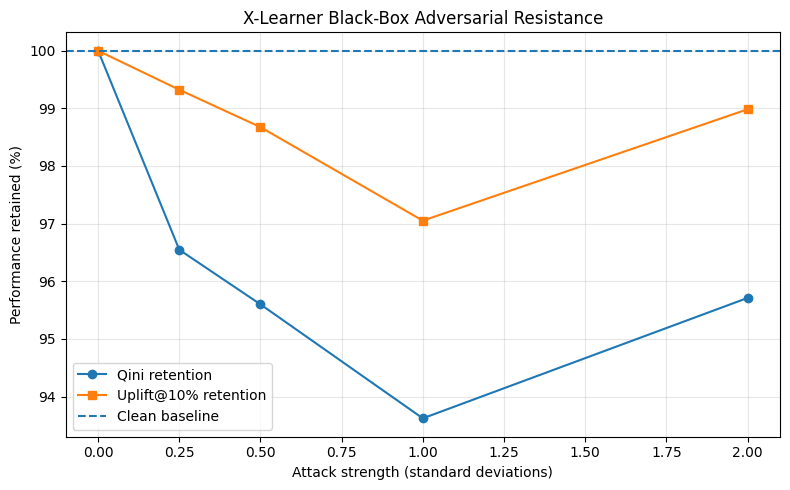

Adversarial evaluation completed!


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display

# 1. Create ONE fixed 1M stratified test sample
n_adv = min(1_000_000, len(yte))
test_strata = 2 * tte.astype(int) + yte.astype(int)

if n_adv < len(yte):
    idx_adv, _ = train_test_split(
        np.arange(len(yte)),
        train_size=n_adv,
        stratify=test_strata,
        random_state=SEED
    )
else:
    idx_adv = np.arange(len(yte))

X_eval = Xte[idx_adv]
t_eval = tte[idx_adv]
y_eval = yte[idx_adv]

print("Stratified training reference:", len(Xs))
print("Stratified test evaluation:", len(X_eval))

# 2. Attack statistics from existing 1M training sample
f9_sd = float(Xs[:, 9].std())
f9_low, f9_high = np.percentile(
    Xs[:, 9], [0.5, 99.5]
)

# 3. Recalculate engineered features
def rebuild_adv_features(R):
    f4, f9, f11 = R[:, 4], R[:, 9], R[:, 11]

    return np.column_stack([
        R,
        f4 * f9,
        f4 * f11,
        f9 * f11,
        f4**2,
        f9**2,
        f11**2
    ]).astype(np.float32)


# 4. Black-box attack against original X-Learner
def black_box_attack(X, strength):
    if strength == 0:
        return X.copy()

    R = X[:, :12]
    shift = strength * f9_sd

    R_plus = R.copy()
    R_minus = R.copy()

    R_plus[:, 9] = np.clip(
        R[:, 9] + shift,
        f9_low, f9_high
    )

    R_minus[:, 9] = np.clip(
        R[:, 9] - shift,
        f9_low, f9_high
    )

    X_plus = rebuild_adv_features(R_plus)
    X_minus = rebuild_adv_features(R_minus)

    # Model-score queries
    s_plus = pred_x(xl, X_plus)
    s_minus = pred_x(xl, X_minus)

    # Choose direction that maximizes predicted uplift
    choose_plus = s_plus >= s_minus

    X_adv = X_minus
    X_adv[choose_plus] = X_plus[choose_plus]

    return X_adv


# 5. Clean baseline
clean_scores = pred_x(xl, X_eval)

clean_qini = qini(
    y_eval, t_eval, clean_scores
)

clean_uplift = uplift_at(
    y_eval, t_eval, clean_scores, 0.1
)

# 6. Evaluate multiple attack strengths
strengths = [0, 0.25, 0.5, 1.0, 2.0]
adv_rows = []

for strength in strengths:
    print(
        f"Evaluating attack strength: {strength}σ",
        flush=True
    )

    X_adv = black_box_attack(X_eval, strength)
    scores = pred_x(xl, X_adv)

    q = qini(y_eval, t_eval, scores)
    u = uplift_at(y_eval, t_eval, scores, 0.1)

    adv_rows.append({
        "attack_strength_sigma": strength,
        "qini": q,
        "qini_retention_%": (
            100 * q / clean_qini
            if clean_qini != 0 else np.nan
        ),
        "uplift@10%": u,
        "uplift_retention_%": (
            100 * u / clean_uplift
            if clean_uplift != 0 else np.nan
        ),
        "mean_score_change": float(
            np.mean(scores - clean_scores)
        ),
        "pct_scores_increased": float(
            100 * np.mean(scores > clean_scores)
        )
    })

    del X_adv, scores

adversarial_results = pd.DataFrame(adv_rows)

display(adversarial_results.round(6))

# 7. Robustness curve
plt.figure(figsize=(8, 5))

plt.plot(
    adversarial_results["attack_strength_sigma"],
    adversarial_results["qini_retention_%"],
    marker="o",
    label="Qini retention"
)

plt.plot(
    adversarial_results["attack_strength_sigma"],
    adversarial_results["uplift_retention_%"],
    marker="s",
    label="Uplift@10% retention"
)

plt.axhline(
    100,
    linestyle="--",
    label="Clean baseline"
)

plt.xlabel("Attack strength (standard deviations)")
plt.ylabel("Performance retained (%)")
plt.title("X-Learner Black-Box Adversarial Resistance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Save results
adversarial_results.to_csv(
    "adversarial_resistance_1m.csv",
    index=False
)

print("Adversarial evaluation completed!")


Visualizations

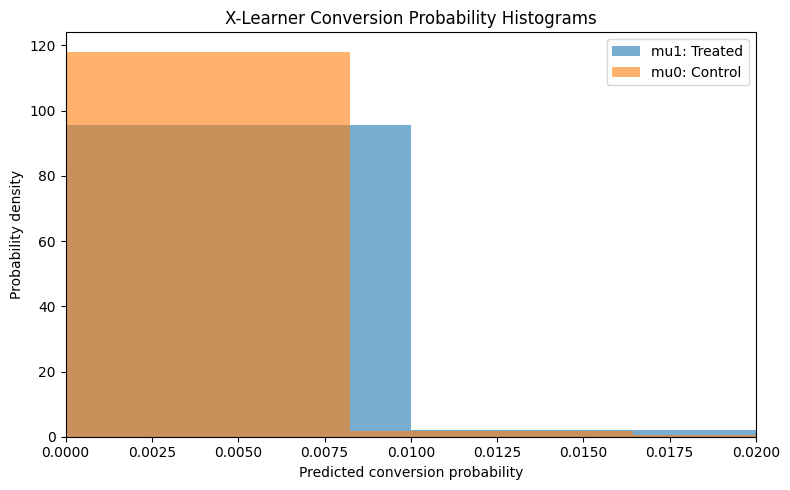

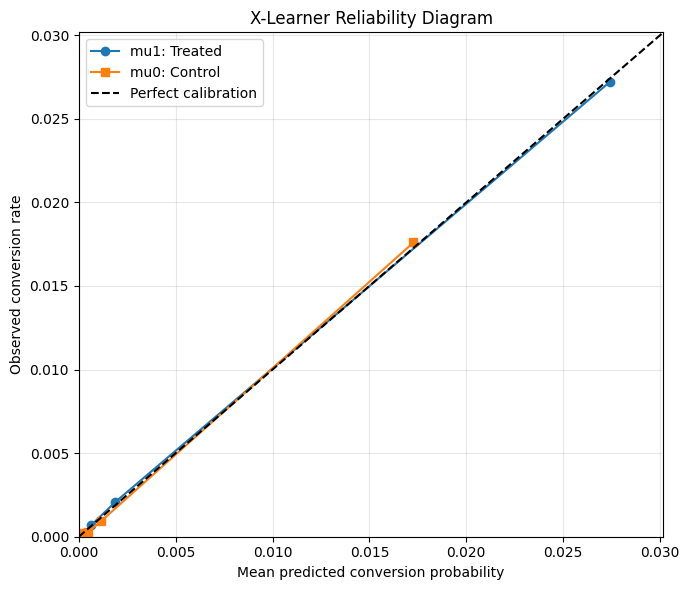

,model,mean_predicted,observed_rate,predicted_to_observed
0,mu1 (Treated),0.003079,0.003089,0.996763
1,mu0 (Control),0.001952,0.001940,1.006003


Generating 2σ adversarial failure examples...


,test_row,failure_type,treatment,f9_clean,f9_attacked,predicted_conversion,actual_conversion,conversion_probability,uplift_clean,uplift_attacked,uplift_change,why_it_failed,mitigation_idea
0,1420178,Treated: Missed conversion,1,44.388660,48.072937,0,1,0.499464,0.105398,0.105398,0.000000,Actual conversion received a low predicted con...,Improve minority-class calibration or investig...
1,1830216,Treated: Missed conversion,1,41.857651,48.072937,0,1,0.498462,0.111213,0.111059,-0.000154,Actual conversion received a low predicted con...,Improve minority-class calibration or investig...
2,755496,Control: Missed conversion,0,47.248463,48.072937,0,1,0.488555,0.001088,0.001088,0.000000,Actual conversion received a low predicted con...,Improve minority-class calibration or investig...
3,1392926,Control: Missed conversion,0,51.025661,37.032013,0,1,0.481528,0.056857,0.053126,-0.003730,Actual conversion received a low predicted con...,Improve minority-class calibration or investig...
4,1111764,Adversarial uplift inflation,0,46.714867,32.721222,0,0,0.203170,0.041696,0.081695,0.039999,Manipulating f9 artificially increased predict...,Validate feature provenance and flag suspiciou...
5,79721,Adversarial uplift inflation,1,46.799473,32.805824,0,0,0.129461,-0.027437,0.009974,0.037411,Manipulating f9 artificially increased predict...,Validate feature provenance and flag suspiciou...
6,995502,Adversarial uplift inflation,0,45.107586,31.113939,0,1,0.191870,-0.013410,0.023360,0.036769,Manipulating f9 artificially increased predict...,Validate feature provenance and flag suspiciou...
7,70210,Adversarial uplift inflation,1,45.366703,31.373056,0,1,0.064036,-0.036175,0.000256,0.036430,Manipulating f9 artificially increased predict...,Validate feature provenance and flag suspiciou...


Question 3 completed.
Stratified training rows: 1000000
Stratified evaluation rows: 1000000
Failure examples: 8


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

T = t_eval == 1
C = t_eval == 0

p1 = xl["mu1"].predict_proba(
    X_eval[T]
)[:, 1]

p0 = xl["mu0"].predict_proba(
    X_eval[C]
)[:, 1]

plt.figure(figsize=(8, 5))

plt.hist(
    p1, bins=100, density=True, alpha=0.6,
    label="mu1: Treated"
)

plt.hist(
    p0, bins=100, density=True, alpha=0.6,
    label="mu0: Control"
)

plt.xlim(0, 0.02)  # Zoom into probabilities near zero

plt.xlabel("Predicted conversion probability")
plt.ylabel("Probability density")
plt.title("X-Learner Conversion Probability Histograms")
plt.legend()
plt.tight_layout()
plt.show()


def calibration_table(y, p, bins=10):
    d = pd.DataFrame({
        "actual": np.asarray(y),
        "predicted": np.asarray(p)
    })

    d["bin"] = pd.qcut(
        d["predicted"],
        q=bins,
        duplicates="drop"
    )

    return d.groupby(
        "bin",
        observed=True
    ).agg(
        mean_predicted=("predicted", "mean"),
        observed_rate=("actual", "mean"),
        count=("actual", "size")
    ).reset_index(drop=True)


cal1 = calibration_table(
    y_eval[T], p1
)

cal0 = calibration_table(
    y_eval[C], p0
)

upper = 1.1 * max(
    cal1["mean_predicted"].max(),
    cal1["observed_rate"].max(),
    cal0["mean_predicted"].max(),
    cal0["observed_rate"].max()
)

plt.figure(figsize=(7, 6))

plt.plot(
    cal1["mean_predicted"],
    cal1["observed_rate"],
    "o-",
    label="mu1: Treated"
)

plt.plot(
    cal0["mean_predicted"],
    cal0["observed_rate"],
    "s-",
    label="mu0: Control"
)

plt.plot(
    [0, upper],
    [0, upper],
    "k--",
    label="Perfect calibration"
)

plt.xlim(0, upper)
plt.ylim(0, upper)

plt.xlabel("Mean predicted conversion probability")
plt.ylabel("Observed conversion rate")
plt.title("X-Learner Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Overall calibration summary
calibration_summary = pd.DataFrame([
    {
        "model": "mu1 (Treated)",
        "mean_predicted": float(p1.mean()),
        "observed_rate": float(y_eval[T].mean())
    },
    {
        "model": "mu0 (Control)",
        "mean_predicted": float(p0.mean()),
        "observed_rate": float(y_eval[C].mean())
    }
])

calibration_summary["predicted_to_observed"] = (
    calibration_summary["mean_predicted"] /
    calibration_summary["observed_rate"].replace(
        0, np.nan
    )
)

display(calibration_summary.round(6))


print("Generating 2σ adversarial failure examples...", flush=True)

X_attack_2 = black_box_attack(X_eval, 2.0)
attack_scores_2 = pred_x(xl, X_attack_2)

# Probability of conversion under observed treatment
p_actual = np.empty(len(y_eval), dtype=float)

p_actual[T] = p1
p_actual[C] = p0

# Illustrative binary threshold
predicted_y = (p_actual >= 0.5).astype(int)

changes = attack_scores_2 - clean_scores

failure_rows = []
used = set()


def add_failure(i, category, reason, mitigation):
    i = int(i)

    if i in used:
        return

    used.add(i)

    failure_rows.append({
        "test_row": int(idx_adv[i]),
        "failure_type": category,
        "treatment": int(t_eval[i]),
        "f9_clean": float(X_eval[i, 9]),
        "f9_attacked": float(X_attack_2[i, 9]),
        "predicted_conversion": int(predicted_y[i]),
        "actual_conversion": int(y_eval[i]),
        "conversion_probability": float(p_actual[i]),
        "uplift_clean": float(clean_scores[i]),
        "uplift_attacked": float(attack_scores_2[i]),
        "uplift_change": float(changes[i]),
        "why_it_failed": reason,
        "mitigation_idea": mitigation
    })


# 4 examples of missed conversions
for group, name in [
    (1, "Treated"),
    (0, "Control")
]:
    candidates = np.where(
        (t_eval == group) &
        (y_eval == 1) &
        (predicted_y == 0)
    )[0]

    candidates = candidates[
        np.argsort(p_actual[candidates])[::-1]
    ]

    for i in candidates[:2]:
        add_failure(
            i,
            f"{name}: Missed conversion",
            "Actual conversion received a low "
            "predicted conversion probability.",
            "Improve minority-class calibration "
            "or investigate decision thresholds."
        )


# Add 4 examples of adversarial uplift inflation
for i in np.argsort(changes)[::-1]:
    if len(failure_rows) >= 8:
        break

    add_failure(
        i,
        "Adversarial uplift inflation",
        "Manipulating f9 artificially increased "
        "predicted uplift.",
        "Validate feature provenance and flag "
        "suspicious feature changes."
    )


failure_examples = pd.DataFrame(failure_rows)

display(failure_examples.round(6))



calibration_summary.to_csv(
    "q3_calibration_1m.csv",
    index=False
)

failure_examples.to_csv(
    "q3_failure_examples_1m.csv",
    index=False
)

print("Question 3 completed.")
print("Stratified training rows:", len(Xs))
print("Stratified evaluation rows:", len(X_eval))
print("Failure examples:", len(failure_examples))


# Primary metrics and confidence intervals

In [17]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42

def q4_metrics(y, t, scores):
    return {
        "Qini": qini(y, t, scores),
        "AUUC": qini(y, t, scores, auuc=True),
        "uplift@10%": uplift_at(y, t, scores, 0.10),
        "uplift@20%": uplift_at(y, t, scores, 0.20),
        "uplift@30%": uplift_at(y, t, scores, 0.30)
    }

predictors = {
    "Original X-Learner": lambda X: pred_x(xl, X),
    "Depth ensemble": ensemble_predict
}

# Original engineered feature reconstruction
def q4_build(R):
    f4, f9, f11 = R[:, 4], R[:, 9], R[:, 11]
    return np.column_stack([
        R,
        f4 * f9, f4 * f11, f9 * f11,
        f4**2, f9**2, f11**2
    ]).astype(np.float32)

# Reference statistics from 1M stratified TRAINING rows
raw_mu = Xs[:, :12].mean(axis=0)
raw_sd = Xs[:, :12].std(axis=0)

rng_q4 = np.random.default_rng(SEED)
R = X_eval[:, :12]

scenario_names = [
    "Clean",
    "Noise 0.5σ",
    "Blur: rounded values",
    "Masking: 10% missing",
    "Feature loss: f9",
    "OOD: shifted +3σ",
    "Black-box 0.25σ",
    "Black-box 0.5σ",
    "Black-box 1σ",
    "Black-box 2σ"
]

# Save selected scores for CI and later examples
q4_scores = {}
q4_rows = []

for scenario in scenario_names:
    print("Evaluating:", scenario, flush=True)

    if scenario == "Clean":
        X_scenario = X_eval

    elif scenario == "Noise 0.5σ":
        X_scenario = q4_build(
            R + rng_q4.normal(
                0, 0.5, size=R.shape
            ) * raw_sd
        )

    elif scenario == "Blur: rounded values":
        X_scenario = q4_build(np.round(R))

    elif scenario == "Masking: 10% missing":
        M = R.copy()
        M[rng_q4.random(M.shape) < 0.10] = np.nan
        X_scenario = q4_build(M)
        del M

    elif scenario == "Feature loss: f9":
        L = R.copy()
        L[:, 9] = raw_mu[9]
        X_scenario = q4_build(L)
        del L

    elif scenario == "OOD: shifted +3σ":
        X_scenario = q4_build(R + 3 * raw_sd)

    else:
        strength = {
            "Black-box 0.25σ": 0.25,
            "Black-box 0.5σ": 0.5,
            "Black-box 1σ": 1.0,
            "Black-box 2σ": 2.0
        }[scenario]
        X_scenario = black_box_attack(X_eval, strength)

    for model_name, predictor in predictors.items():
        scores = predictor(X_scenario)

        q4_rows.append({
            "scenario": scenario,
            "model": model_name,
            **q4_metrics(y_eval, t_eval, scores)
        })

        if scenario in ["Clean", "Black-box 2σ"]:
            q4_scores[(scenario, model_name)] = scores.copy()

    if X_scenario is not X_eval:
        del X_scenario

q4_primary = pd.DataFrame(q4_rows)
display(q4_primary.round(6))


if "stress" in globals():
    rarity = stress.loc[
        stress.index.astype(str).str.startswith("Rarity:")
    ]
    if len(rarity):
        print("Additional retrained rarity experiments:")
        display(rarity)

ci_n = min(100_000, len(y_eval))
strata_ci = 2 * t_eval.astype(int) + y_eval.astype(int)

if ci_n < len(y_eval):
    ci_idx, _ = train_test_split(
        np.arange(len(y_eval)),
        train_size=ci_n,
        stratify=strata_ci,
        random_state=SEED
    )
else:
    ci_idx = np.arange(len(y_eval))

rng_ci = np.random.default_rng(SEED)
ci_y = y_eval[ci_idx]
ci_t = t_eval[ci_idx]

# Resample within treatment/outcome strata
stratum_ids = 2 * ci_t.astype(int) + ci_y.astype(int)
groups = [
    np.where(stratum_ids == g)[0]
    for g in range(4)
]

bootstrap_indices = []
for b in range(50):
    sampled = np.concatenate([
        rng_ci.choice(g, size=len(g), replace=True)
        for g in groups if len(g)
    ])
    bootstrap_indices.append(sampled)

ci_rows = []

for key, full_scores in q4_scores.items():
    sc, model_name = key
    s = full_scores[ci_idx]

    bq = []
    bu = []

    for ii in bootstrap_indices:
        bq.append(qini(ci_y[ii], ci_t[ii], s[ii]))
        bu.append(
            uplift_at(ci_y[ii], ci_t[ii], s[ii], 0.10)
        )

    ci_rows.append({
        "scenario": sc,
        "model": model_name,
        "Qini_95%_low": np.percentile(bq, 2.5),
        "Qini_95%_high": np.percentile(bq, 97.5),
        "uplift10_95%_low": np.percentile(bu, 2.5),
        "uplift10_95%_high": np.percentile(bu, 97.5),
        "bootstrap_rows": ci_n,
        "bootstrap_repeats": 50
    })

q4_ci = pd.DataFrame(ci_rows)

print("95% bootstrap confidence intervals:")
display(q4_ci.round(6))

q4_primary.to_csv("q4_primary_metrics.csv", index=False)
q4_ci.to_csv("q4_bootstrap_ci.csv", index=False)


Evaluating: Clean
Evaluating: Noise 0.5σ
Evaluating: Blur: rounded values
Evaluating: Masking: 10% missing
Evaluating: Feature loss: f9
Evaluating: OOD: shifted +3σ
Evaluating: Black-box 0.25σ
Evaluating: Black-box 0.5σ
Evaluating: Black-box 1σ
Evaluating: Black-box 2σ


,scenario,model,Qini,AUUC,uplift@10%,uplift@20%,uplift@30%
0,Clean,Original X-Learner,0.000381,0.000444,0.008017,0.004758,0.003352
1,Clean,Depth ensemble,0.000368,0.000429,0.007777,0.004772,0.003320
2,Noise 0.5σ,Original X-Learner,0.000357,0.000417,0.007736,0.004474,0.003238
3,Noise 0.5σ,Depth ensemble,0.000367,0.000428,0.007578,0.004417,0.003273
4,Blur: rounded values,Original X-Learner,0.000247,0.000286,0.006779,0.004157,0.002892
5,Blur: rounded values,Depth ensemble,0.000314,0.000365,0.007142,0.004568,0.003160
6,Masking: 10% missing,Original X-Learner,0.000331,0.000389,0.006942,0.004581,0.003298
7,Masking: 10% missing,Depth ensemble,0.000324,0.000381,0.006989,0.004293,0.003231
8,Feature loss: f9,Original X-Learner,0.000378,0.000440,0.007739,0.004692,0.003496
9,Feature loss: f9,Depth ensemble,0.000364,0.000424,0.007383,0.004817,0.003478


Additional retrained rarity experiments:


,qini,qini_%_of_clean,uplift@10%,top10_lift_x,mu1_AUROC,mu1_calibration,preflight_PASS
scenario,,,,,,,
Rarity: 25% of conversions,-0.000057,-15.1,0.004091,3.55832,0.939630,0.996585,True
Rarity: control 15% -> 5%,0.000391,104.1,0.008402,7.30739,0.957441,1.000449,True


95% bootstrap confidence intervals:


,scenario,model,Qini_95%_low,Qini_95%_high,uplift10_95%_low,uplift10_95%_high,bootstrap_rows,bootstrap_repeats
0,Clean,Original X-Learner,0.000604,0.000834,0.004232,0.009129,100000,50
1,Clean,Depth ensemble,0.000591,0.000708,0.002422,0.007183,100000,50
2,Black-box 2σ,Original X-Learner,0.000596,0.000744,0.003034,0.007979,100000,50
3,Black-box 2σ,Depth ensemble,0.000585,0.000712,0.003450,0.008778,100000,50


# Latency and Throughput

In [18]:
import time
import platform
import numpy as np
import pandas as pd
import psutil
from IPython.display import display

SEED = 42
N_BENCH = 2048
REPEATS = 50
BATCH_SIZES = [1, 32, 256]

# 1. Prepare benchmark inputs OUTSIDE the timer
N = min(N_BENCH, len(X_eval))
X_clean = np.ascontiguousarray(X_eval[:N])

# Reuse reference standard deviations from the
# existing 1M-row stratified training sample (Xs)
rng_bench = np.random.default_rng(SEED)
sd_bench = Xs[:, :12].std(axis=0)

R_noisy = (
    X_clean[:, :12]
    + rng_bench.normal(
        0, 0.5, size=(N, 12)
    ) * sd_bench
)

# q4_build() already exists in your notebook
X_noise = np.ascontiguousarray(
    q4_build(R_noisy)
)

# Generate the adversarial batch BEFORE timing
X_attack = np.ascontiguousarray(
    black_box_attack(X_clean, 2.0)
)

# 2. Models already loaded/trained in your notebook
models_bench = {
    "Original X-Learner": lambda X: pred_x(xl, X),
    "Depth ensemble": ensemble_predict
}

conditions_bench = {
    "Clean": X_clean,
    "Noise 0.5σ": X_noise,
    "Black-box 2σ": X_attack
}

# 3. Benchmark model inference only
def benchmark_inference(predict, X, batch_size, repeats=50):
    bs = min(batch_size, len(X))
    N = len(X)

    # Prepare batches OUTSIDE timed section
    batches = [
        np.ascontiguousarray(X[i:i+bs])
        for i in range(0, N, bs)
    ]

    # Warm up models before measuring
    for _ in range(5):
        predict(batches[0])

    latencies = []

    # Measure model prediction time only
    for i in range(repeats):
        batch = batches[i % len(batches)]

        start = time.perf_counter()
        predict(batch)
        elapsed = time.perf_counter() - start

        latencies.append(elapsed * 1000)

    # Throughput: warm model, prebuilt batches
    # Multiple passes reduce measurement noise
    passes = 5

    start = time.perf_counter()

    for _ in range(passes):
        for batch in batches:
            predict(batch)

    total_seconds = time.perf_counter() - start

    return {
        "batch_size": bs,
        "p50_latency_ms": float(
            np.percentile(latencies, 50)
        ),
        "p90_latency_ms": float(
            np.percentile(latencies, 90)
        ),
        "p50_per_sample_ms": float(
            np.percentile(latencies, 50) / bs
        ),
        "p90_per_sample_ms": float(
            np.percentile(latencies, 90) / bs
        ),
        "throughput_samples_sec": float(
            passes * N / total_seconds
        )
    }


# 4. Execute benchmarks
print("Hardware:", platform.processor() or platform.machine())
print("Logical CPU cores:", psutil.cpu_count())
print("Benchmark observations:", N)
print("XGBoost inference: CPU")
print("Attack generation excluded from timing.")

benchmark_rows = []

for model_name, predictor in models_bench.items():
    for condition, X in conditions_bench.items():
        for bs in BATCH_SIZES:

            print(
                f"Benchmarking {model_name} | "
                f"{condition} | batch {bs}",
                flush=True
            )

            metrics = benchmark_inference(
                predictor,
                X,
                batch_size=bs,
                repeats=REPEATS
            )

            benchmark_rows.append({
                "model": model_name,
                "condition": condition,
                **metrics
            })


# 5. Results table
q4_latency = pd.DataFrame(benchmark_rows)

display(q4_latency.round(4))


# 6. Percentage overhead of ensemble vs original
original = q4_latency[
    q4_latency["model"] == "Original X-Learner"
].set_index(["condition", "batch_size"])

ensemble = q4_latency[
    q4_latency["model"] == "Depth ensemble"
].set_index(["condition", "batch_size"])

q4_overhead = pd.DataFrame({
    "ensemble_p50_overhead_%": (
        100 * (
            ensemble["p50_latency_ms"]
            / original["p50_latency_ms"] - 1
        )
    ),
    "ensemble_p90_overhead_%": (
        100 * (
            ensemble["p90_latency_ms"]
            / original["p90_latency_ms"] - 1
        )
    ),
    "ensemble_throughput_change_%": (
        100 * (
            ensemble["throughput_samples_sec"]
            / original["throughput_samples_sec"] - 1
        )
    )
}).reset_index()

print("Ensemble versus original:")
display(q4_overhead.round(2))


# 7. Save results
q4_latency.to_csv(
    "q4_latency_throughput.csv",
    index=False
)

q4_overhead.to_csv(
    "q4_ensemble_overhead.csv",
    index=False
)

print("Inference efficiency evaluation completed.")


Hardware: x86_64
Logical CPU cores: 2
Benchmark observations: 2048
XGBoost inference: CPU
Attack generation excluded from timing.
Benchmarking Original X-Learner | Clean | batch 1
Benchmarking Original X-Learner | Clean | batch 32
Benchmarking Original X-Learner | Clean | batch 256
Benchmarking Original X-Learner | Noise 0.5σ | batch 1
Benchmarking Original X-Learner | Noise 0.5σ | batch 32
Benchmarking Original X-Learner | Noise 0.5σ | batch 256
Benchmarking Original X-Learner | Black-box 2σ | batch 1
Benchmarking Original X-Learner | Black-box 2σ | batch 32
Benchmarking Original X-Learner | Black-box 2σ | batch 256
Benchmarking Depth ensemble | Clean | batch 1
Benchmarking Depth ensemble | Clean | batch 32
Benchmarking Depth ensemble | Clean | batch 256
Benchmarking Depth ensemble | Noise 0.5σ | batch 1
Benchmarking Depth ensemble | Noise 0.5σ | batch 32
Benchmarking Depth ensemble | Noise 0.5σ | batch 256
Benchmarking Depth ensemble | Black-box 2σ | batch 1
Benchmarking Depth ensemb

,model,condition,batch_size,p50_latency_ms,p90_latency_ms,p50_per_sample_ms,p90_per_sample_ms,throughput_samples_sec
0,Original X-Learner,Clean,1,1.5111,3.7506,1.5111,3.7506,1361.9648
1,Original X-Learner,Clean,32,0.8021,1.8452,0.0251,0.0577,38305.2727
2,Original X-Learner,Clean,256,1.1881,1.3014,0.0046,0.0051,214839.0417
3,Original X-Learner,Noise 0.5σ,1,0.6604,0.6875,0.6604,0.6875,1003.8881
4,Original X-Learner,Noise 0.5σ,32,0.7611,0.7852,0.0238,0.0245,39456.8688
5,Original X-Learner,Noise 0.5σ,256,1.1971,1.3134,0.0047,0.0051,209791.9061
6,Original X-Learner,Black-box 2σ,1,0.6743,0.7160,0.6743,0.7160,946.9928
7,Original X-Learner,Black-box 2σ,32,0.7803,0.7995,0.0244,0.0250,35606.6303
8,Original X-Learner,Black-box 2σ,256,6.4450,22.0188,0.0252,0.0860,43517.5932
9,Depth ensemble,Clean,1,1.3555,1.5661,1.3555,1.5661,583.7868


Ensemble versus original:


,condition,batch_size,ensemble_p50_overhead_%,ensemble_p90_overhead_%,ensemble_throughput_change_%
0,Clean,1,-10.30,-58.24,-57.14
1,Clean,32,85.93,-16.18,-50.54
2,Clean,256,84.47,79.20,-47.78
3,Noise 0.5σ,1,101.12,153.58,-50.36
4,Noise 0.5σ,32,99.03,102.66,-51.81
5,Noise 0.5σ,256,86.21,80.86,-46.84
6,Black-box 2σ,1,96.41,95.61,-38.22
7,Black-box 2σ,32,94.25,107.96,-47.71
8,Black-box 2σ,256,-65.82,-88.81,95.22


Inference efficiency evaluation completed.


# Updated Model

In [19]:
from pathlib import Path
import subprocess
import zipfile
import json
import pandas as pd
import numpy as np
from IPython.display import display

repo = Path("/content/INSE-6450")

if repo.exists():
    subprocess.run(
        ["git", "-C", str(repo), "pull", "--ff-only"],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone",
         "https://github.com/saopa28/INSE-6450.git",
         str(repo)],
        check=True
    )

github_folder = repo / "Milestone 3"
output_folder = Path("/content/aws_model_comparison")
output_folder.mkdir(parents=True, exist_ok=True)

for zip_name in [
    "updated_comparison.zip",
    "updated_xlearner.zip"
]:
    zip_path = github_folder / zip_name
    assert zip_path.is_file(), f"Missing: {zip_path}"

    destination = output_folder / zip_path.stem
    destination.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path) as z:
        # GitHub ZIP files are project artifacts you uploaded.
        for member in z.infolist():
            target = (
                destination / member.filename
            ).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError("Unsafe ZIP entry")
        z.extractall(destination)

    print("Extracted:", zip_name)

def find_aws_file(filename):
    matches = list(
        (output_folder / "updated_comparison").rglob(filename)
    )
    if not matches:
        raise FileNotFoundError(
            f"{filename} not found in updated_comparison.zip"
        )
    return matches[0]

primary_aws = pd.read_csv(find_aws_file("primary_metrics.csv"))
latency_aws = pd.read_csv(find_aws_file("latency_throughput.csv"))
size_aws = pd.read_csv(find_aws_file("model_size.csv"))
ram_aws = pd.read_csv(find_aws_file("process_RAM.csv"))
failures_aws = pd.read_csv(find_aws_file("failure_cases_8.csv"))
ci_aws = pd.read_csv(find_aws_file("paired_bootstrap_ci.csv"))

with open(find_aws_file("run_manifest.json")) as f:
    aws_manifest = json.load(f)

print("\nAWS results successfully loaded!")
print("Updated deployment:", aws_manifest["selected_deployment"])
print("Inference hardware:", aws_manifest["hardware"]["inference_device"])
print("Primary metric rows:", len(primary_aws))
print("Failure cases:", len(failures_aws))


Extracted: updated_comparison.zip
Extracted: updated_xlearner.zip

AWS results successfully loaded!
Updated deployment: primary
Inference hardware: CPU
Primary metric rows: 50
Failure cases: 8


In [20]:

#Primary metrics comparison

models_to_compare = [
    "Original X-Learner",
    "Updated Selected"
]

primary = primary_aws[
    primary_aws["model"].isin(models_to_compare)
].copy()

# One row per scenario, one set of metrics per model
metric_names = [
    "qini",
    "AUUC",
    "uplift_at_10",
    "uplift_at_20",
    "uplift_at_30"
]

comparison_table = primary.pivot(
    index="scenario",
    columns="model",
    values=metric_names
)

print("TABLE 2.7.1 — Original vs Updated X-Learner")
display(comparison_table.round(6))

# Compact comparison with measured differences
qini_table = primary.pivot(
    index="scenario",
    columns="model",
    values="qini"
)

qini_table["Qini difference"] = (
    qini_table["Updated Selected"]
    - qini_table["Original X-Learner"]
)

print("Qini improvement / degradation")
display(qini_table.round(7))

# Confidence intervals from the saved AWS evaluation
print("Paired 95% bootstrap confidence intervals")
display(
    ci_aws[
        ci_aws["metric"] == "paired Qini difference"
    ][[
        "scenario",
        "point_on_CI_subset",
        "ci_low",
        "ci_high",
        "ci_rows"
    ]].round(7)
)


TABLE 2.7.1 — Original vs Updated X-Learner


qini                                AUUC  \
model           Original X-Learner Updated Selected Original X-Learner   
scenario                                                                 
Blackbox 0.25             0.000368         0.000368           0.000429   
Blackbox 0.5              0.000364         0.000364           0.000424   
Blackbox 1.0              0.000357         0.000357           0.000415   
Blackbox 2.0              0.000365         0.000365           0.000425   
Blur rounded              0.000247         0.000247           0.000286   
Clean                     0.000381         0.000381           0.000444   
Feature loss f9           0.000378         0.000378           0.000440   
Masking 10pct             0.000303         0.000303           0.000355   
Noise 0.5sigma            0.000356         0.000356           0.000416   
OOD +3sigma              -0.000054        -0.000054          -0.000064   

                                       uplift_at_10                   \
model           Updated Selected Original X-Learner Updated Selected   
scenario                                                               
Blackbox 0.25           0.000429           0.007963         0.007963   
Blackbox 0.5            0.000424           0.007914         0.007914   
Blackbox 1.0            0.000415           0.007779         0.007779   
Blackbox 2.0            0.000425           0.007962         0.007962   
Blur rounded            0.000286           0.006779         0.006779   
Clean                   0.000444           0.008017         0.008017   
Feature loss f9         0.000440           0.007739         0.007739   
Masking 10pct           0.000355           0.006596         0.006596   
Noise 0.5sigma          0.000416           0.007762         0.007762   
OOD +3sigma            -0.000064           0.004230         0.004230   

                      uplift_at_20                        uplift_at_30  \
model           Original X-Learner Updated Selected Original X-Learner   
scenario                                                                 
Blackbox 0.25             0.004663         0.004663           0.003292   
Blackbox 0.5              0.004709         0.004709           0.003287   
Blackbox 1.0              0.004537         0.004537           0.003245   
Blackbox 2.0              0.004637         0.004637           0.003282   
Blur rounded              0.004157         0.004157           0.002892   
Clean                     0.004758         0.004758           0.003352   
Feature loss f9           0.004692         0.004692           0.003496   
Masking 10pct             0.004243         0.004243           0.003236   
Noise 0.5sigma            0.004490         0.004490           0.003242   
OOD +3sigma               0.002256         0.002256           0.001589   

                                  
model           Updated Selected  
scenario                          
Blackbox 0.25           0.003292  
Blackbox 0.5            0.003287  
Blackbox 1.0            0.003245  
Blackbox 2.0            0.003282  
Blur rounded            0.002892  
Clean                   0.003352  
Feature loss f9         0.003496  
Masking 10pct           0.003236  
Noise 0.5sigma          0.003242  
OOD +3sigma             0.001589

Qini improvement / degradation


model,Original X-Learner,Updated Selected,Qini difference
scenario,,,
Blackbox 0.25,0.000368,0.000368,0.0
Blackbox 0.5,0.000364,0.000364,0.0
Blackbox 1.0,0.000357,0.000357,0.0
Blackbox 2.0,0.000365,0.000365,0.0
Blur rounded,0.000246,0.000246,0.0
Clean,0.000381,0.000381,0.0
Feature loss f9,0.000378,0.000378,0.0
Masking 10pct,0.000303,0.000303,0.0
Noise 0.5sigma,0.000356,0.000356,0.0


Paired 95% bootstrap confidence intervals


,scenario,point_on_CI_subset,ci_low,ci_high,ci_rows
4,Clean,0.0,0.0,0.0,100000
9,Blackbox 2.0,0.0,0.0,0.0,100000


Memory and model size differences

In [21]:

# Model size, RAM, latency, throughput

print("TABLE 2.7.2 — Serialized model size (MB)")
display(size_aws.round(3))

original_size = size_aws.loc[
    size_aws["model"] == "Original X-Learner",
    "serialized_size_MB"
].iloc[0]

updated_size = size_aws.loc[
    size_aws["model"] == "Updated Selected",
    "serialized_size_MB"
].iloc[0]

size_change_pct = (
    100 * (updated_size / original_size - 1)
)

size_summary = pd.DataFrame([{
    "Original size (MB)": original_size,
    "Updated size (MB)": updated_size,
    "Change (%)": size_change_pct
}])

display(size_summary.round(3))


print("TABLE 2.7.3 — Process RAM measurements")
display(ram_aws.round(3))


# Summarize batch-256 model-only efficiency
batch256 = latency_aws[
    latency_aws["batch_size"] == 256
].copy()

efficiency_comparison = batch256.pivot(
    index="condition",
    columns="model",
    values=[
        "p50_latency_ms",
        "p90_latency_ms",
        "throughput_rows_per_s"
    ]
)

print("TABLE 2.7.4 — Inference efficiency, batch 256")
display(efficiency_comparison.round(3))

print(
    "Model size change:",
    f"{size_change_pct:+.2f}%"
)


TABLE 2.7.2 — Serialized model size (MB)


,model,serialized_size_MB
0,Original X-Learner,1.460
1,Updated Primary,1.460
2,Shallow Companion,0.628
3,Depth Ensemble,2.088
4,Updated Selected,1.460


,Original size (MB),Updated size (MB),Change (%)
0,1.46,1.46,0.0


TABLE 2.7.3 — Process RAM measurements


,model,condition,baseline_process_RAM_MB,peak_process_RAM_MB,incremental_RAM_MB
0,Original X-Learner,Clean,2252.714,2252.861,0.147
1,Original X-Learner,Noise 0.5sigma,2252.861,2252.861,0.000
2,Original X-Learner,Blackbox 2.0,2252.861,2252.861,0.000
3,Updated Selected,Clean,2252.861,2252.861,0.000
4,Updated Selected,Noise 0.5sigma,2252.861,2252.861,0.000
5,Updated Selected,Blackbox 2.0,2252.861,2252.861,0.000


TABLE 2.7.4 — Inference efficiency, batch 256


p50_latency_ms                      p90_latency_ms  \
model          Original X-Learner Updated Selected Original X-Learner   
condition                                                               
Blackbox 2.0                0.351            0.375              0.392   
Clean                       0.362            0.358              0.398   
Noise 0.5sigma              0.361            0.375              0.386   

                                throughput_rows_per_s                   
model          Updated Selected    Original X-Learner Updated Selected  
condition                                                               
Blackbox 2.0              0.399            715514.257       680596.349  
Clean                     0.390            690420.026       713570.576  
Noise 0.5sigma            0.417            716371.091       676231.032

Model size change: +0.00%


Failure Examples

In [22]:

# Failure examples and resolved cases

failure_table = failures_aws.copy()

# Confidence in the predicted conversion class
# This is NOT confidence in the uplift estimate.
p = failure_table[
    "predicted_conversion_probability"
].astype(float)

predicted = failure_table[
    "predicted_conversion"
].astype(int)

failure_table["prediction_confidence"] = np.where(
    predicted == 1, p, 1 - p
)

columns = [
    "test_row",
    "case_type",
    "treatment",
    "f4_before",
    "f9_before",
    "f9_after",
    "f11_before",
    "predicted_conversion",
    "actual_conversion",
    "prediction_confidence",
    "baseline_uplift",
    "modified_input_original_uplift",
    "modified_input_updated_uplift",
    "updated_action",
    "reason",
    "mitigation",
    "adaptation_result"
]

print("TABLE 2.8.1 — Eight representative failure cases")
display(failure_table[columns].round(6))

resolved = failure_table[
    failure_table["adaptation_result"]
    .astype(str).str.startswith("Resolved")
].copy()

print("TABLE 2.8.2 — Cases resolved after adaptation")
display(resolved[[
    "test_row",
    "case_type",
    "f9_before",
    "f9_after",
    "modified_input_original_uplift",
    "updated_action",
    "reason",
    "adaptation_result"
]].round(6))

print("Total cases:", len(failure_table))
print("Resolved cases:", len(resolved))

assert len(failure_table) == 8
assert len(resolved) >= 2

# Save formatted tables
comparison_table.to_csv("aws_model_comparison_table.csv")
size_summary.to_csv("aws_model_size_summary.csv", index=False)
failure_table.to_csv("aws_formatted_failure_cases.csv", index=False)


TABLE 2.8.1 — Eight representative failure cases


,test_row,case_type,treatment,f4_before,f9_before,f9_after,f11_before,predicted_conversion,actual_conversion,prediction_confidence,baseline_uplift,modified_input_original_uplift,modified_input_updated_uplift,updated_action,reason,mitigation,adaptation_result
0,1420178,Treated missed conversion,1,14.234099,44.388660,44.388660,-0.624187,0,1,0.500536,0.105398,0.105398,0.105398,score,Rare positive conversion missed at 0.5 threshold,Validate rare-class operating threshold; retai...,Unresolved
1,1830216,Treated missed conversion,1,14.710415,41.857651,41.857651,-0.337358,0,1,0.501538,0.111213,0.111213,0.111213,score,Rare positive conversion missed at 0.5 threshold,Validate rare-class operating threshold; retai...,Unresolved
2,755496,Control missed conversion,0,13.429890,47.248463,47.248463,-0.583534,0,1,0.511445,0.001088,0.001088,0.001088,score,Rare positive conversion missed at 0.5 threshold,Validate rare-class operating threshold; retai...,Unresolved
3,1392926,Control missed conversion,0,16.822119,51.025661,51.025661,-0.560340,0,1,0.518472,0.056857,0.056857,0.056857,score,Rare positive conversion missed at 0.5 threshold,Validate rare-class operating threshold; retai...,Unresolved
4,1111764,Black-box f9 score inflation,0,14.439578,46.714867,32.676403,-0.391661,0,0,0.796830,0.041696,0.081695,0.081695,score,Feature manipulation increases predicted uplift,"Feature provenance, drift check and abstention",Unresolved
5,79721,Black-box f9 score inflation,1,12.310110,46.799473,32.761009,-0.436029,0,0,0.870539,-0.027437,0.009974,0.009974,score,Feature manipulation increases predicted uplift,"Feature provenance, drift check and abstention",Unresolved
6,871241,Detected invalid nan,1,10.280525,13.190056,NaN,-0.168679,0,0,0.999746,0.000176,-0.001226,NaN,ABSTAIN,NaN feature,Input guard rejects corrupted row before targe...,Resolved: rejected before targeting
7,1518662,Detected invalid range,1,10.280525,13.190056,7604.797363,-0.168679,0,0,0.999871,0.000176,-0.000678,NaN,ABSTAIN,Feature far beyond training range,Input guard rejects corrupted row before targe...,Resolved: rejected before targeting


TABLE 2.8.2 — Cases resolved after adaptation


,test_row,case_type,f9_before,f9_after,modified_input_original_uplift,updated_action,reason,adaptation_result
6,871241,Detected invalid nan,13.190056,NaN,-0.001226,ABSTAIN,NaN feature,Resolved: rejected before targeting
7,1518662,Detected invalid range,13.190056,7604.797363,-0.000678,ABSTAIN,Feature far beyond training range,Resolved: rejected before targeting


Total cases: 8
Resolved cases: 2
